In [1]:
import yfinance as yf 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt


data = yf.download(['TTE.PA', 'MC.PA', 'RMS.PA', 'OR.PA', 'SAN.PA','AIR.PA', 'BNP.PA', 'SU.PA', 'AI.PA', 'CAP.PA', '^FCHI'], start ='2021-01-01', end = '2026-01-01', auto_adjust = False)
price = data['Adj Close'] 
missing_values = price.isnull().sum()

if missing_values.sum() != 0:
    print(f'There are {missing_values.sum()} missing values, {missing_values}')
else:
    print('he data is ready to use')

returns = price.pct_change()

annualized_r = returns.mean()*252
annualized_vol = returns.std()*np.sqrt(252)

summary = pd.DataFrame ({'annualized returns in % ':annualized_r *100 , 'Annualized volatility in %':annualized_vol*100}).round(2).sort_values('annualized returns in % ',ascending = False)
summary                     

[*********************100%***********************]  11 of 11 completed

he data is ready to use


,annualized returns in %,Annualized volatility in %
Ticker,,
BNP.PA,23.23,28.13
RMS.PA,21.79,27.53
AIR.PA,21.04,28.63
SU.PA,18.71,27.89
TTE.PA,18.16,24.10
MC.PA,10.46,29.12
AI.PA,10.41,18.45
^FCHI,8.72,16.08
CAP.PA,7.55,27.69


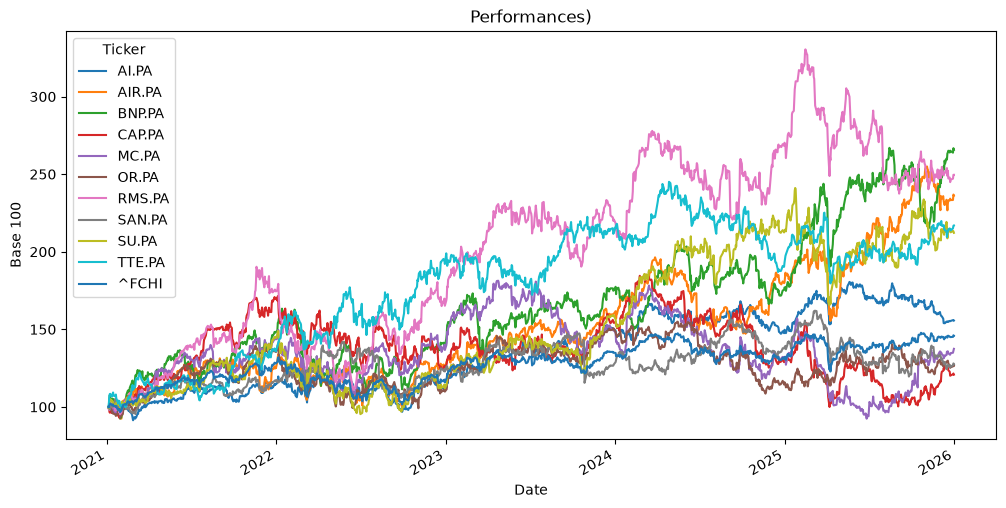

In [2]:
normalized_price = price/price.iloc[0] * 100 

normalized_price.plot(figsize=(12, 6), title="Performances)")
plt.ylabel("Base 100")
plt.show()